# NetRank demo

Graph exploration, the GDS results, match prediction and the agent, run against the local stack
(`make docker-run`, `make ingest`, `make gds`, `make train`).

**No cell calls Groq.** The agent section replays recorded model turns through the real agent, tools and
guardrails, and each replay says where its turns come from.

In [1]:
import json
import logging
import statistics
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from app.config import get_settings
from app.database.client import Neo4jClient
from app.services import analytics, gds, predict

pd.set_option("display.max_colwidth", 80)
logging.getLogger("neo4j").setLevel(logging.ERROR)  # EXPLAIN warnings are shown by the guardrail cells themselves
db = Neo4jClient.from_settings(get_settings())

## 1. The graph

Node and relationship counts, read from the database.

In [2]:
labels = db.read("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS count ORDER BY count DESC")
rels = db.read("MATCH ()-[r]->() RETURN type(r) AS type, count(*) AS count ORDER BY count DESC")
display(pd.DataFrame(labels), pd.DataFrame(rels))

,label,count
0,Match,102417
1,Tournament,2494
2,Player,2316
3,Bookmaker,4


,type,count
0,PRICED,181474
1,PART_OF,102417
2,WON,102417
3,LOST,102417
4,BEAT,66624
5,SIMILAR_STYLE,7120


### Matches per season

One `Match` node per played match, linked to its yearly `Tournament`. Odds rows are linked from 2000, but
the four bookmakers kept in the graph price matches from 2002 (Bet365), 2004 (Pinnacle, Expekt) and 2007 (Ladbrokes).

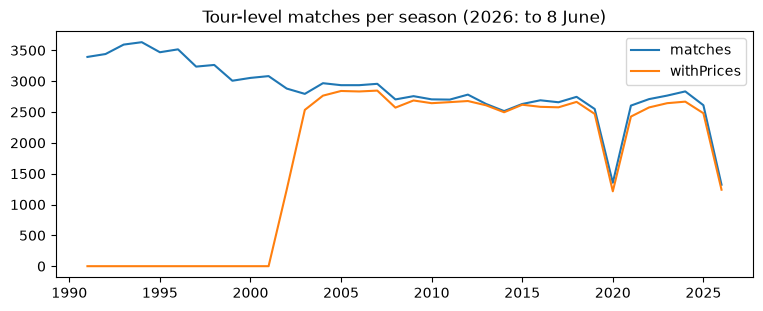

In [3]:
seasons = pd.DataFrame(db.read('''
MATCH (m:Match)
RETURN m.date.year AS season, count(*) AS matches, sum(CASE WHEN EXISTS { (m)<-[:PRICED]-() } THEN 1 ELSE 0 END) AS withPrices
ORDER BY season'''))
ax = seasons.plot(x="season", y=["matches", "withPrices"], figsize=(9, 3.2), title="Tour-level matches per season (2026: to 8 June)")
ax.set_xlabel("")
plt.show()

### Who beat whom

`BEAT` is derived from the matches (walkovers excluded) and carries the number of wins. The degree
distribution is heavy-tailed: most players beat a handful of others, a few beat hundreds.

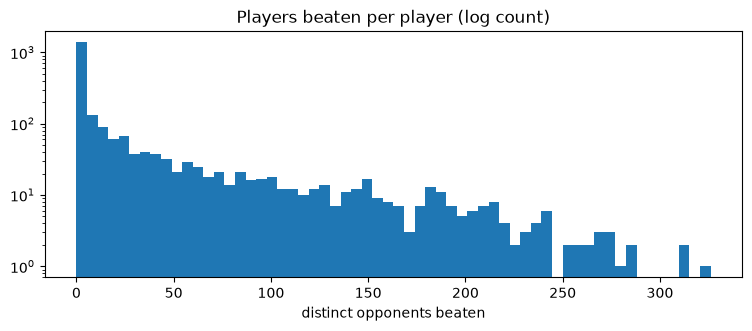

,player,beaten,lostTo
1143,Roger Federer,326,111
1424,Rafael Nadal,312,98
1471,Novak Djokovic,312,100
1426,Richard Gasquet,283,180
1435,Gael Monfils,283,170


In [4]:
degrees = pd.DataFrame(db.read('''
MATCH (p:Player)
RETURN p.name AS player, COUNT { (p)-[:BEAT]->() } AS beaten, COUNT { (p)<-[:BEAT]-() } AS lostTo'''))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(degrees["beaten"], bins=60, log=True)
ax.set(title="Players beaten per player (log count)", xlabel="distinct opponents beaten")
plt.show()
degrees.sort_values("beaten", ascending=False).head(5)

## 2. Prestige (PageRank on `BEAT`)

All-time board, then one era, from the same service as `GET /api/players/{id}/prestige`.

In [5]:
def board(era=None, size=10):
    result = analytics.prestige_board(db, analytics.parse_era(era) if era else None, 1, size)
    return pd.DataFrame([{"rank": e.rank, "player": e.player.name, "score": round(e.score, 4)}
                         for e in result.ranking.items])

display(board(), board("2010s"))

,rank,player,score
0,1,Novak Djokovic,29.5540
1,2,Roger Federer,29.4352
2,3,Rafael Nadal,26.3673
3,4,Andy Murray,16.2573
4,5,Pete Sampras,15.9599
5,6,Andre Agassi,15.1756
6,7,David Ferrer,13.5956
7,8,Alexander Zverev,12.9278
8,9,Lleyton Hewitt,12.1976
9,10,Yevgeny Kafelnikov,12.1798


,rank,player,score
0,1,Novak Djokovic,25.3400
1,2,Rafael Nadal,20.5615
2,3,Roger Federer,20.5239
3,4,Andy Murray,14.7784
4,5,Tomas Berdych,11.7777
5,6,David Ferrer,11.1489
6,7,Stan Wawrinka,10.9326
7,8,Kei Nishikori,10.1327
8,9,Jo-Wilfried Tsonga,9.9389
9,10,Marin Cilic,9.5381


### The top of the graph

`BEAT` edges among the 12 most prestigious players. Edge width = wins. Node size = prestige.

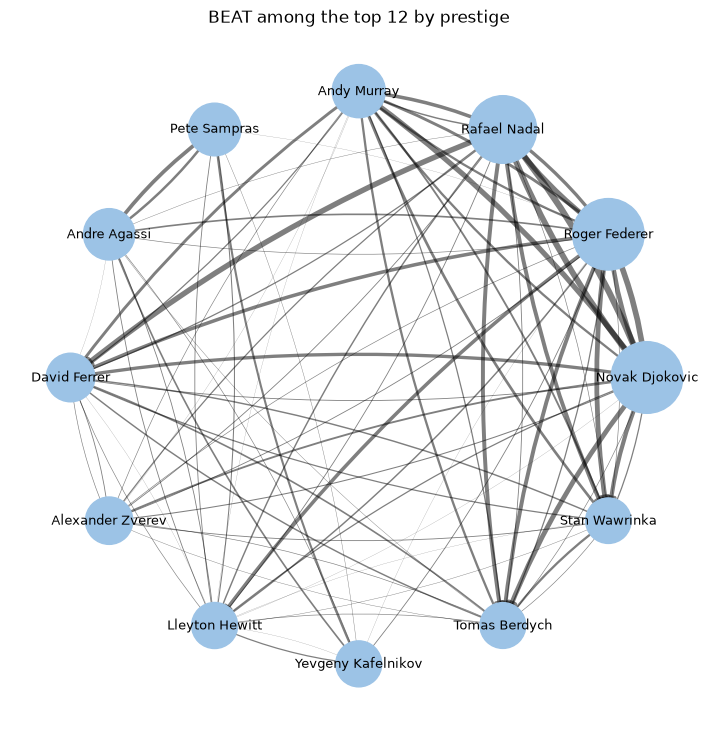

In [6]:
top = db.read('''
MATCH (p:Player) WHERE p.prestigeRank <= 12
RETURN p.id AS id, p.name AS name, p.prestige AS prestige ORDER BY p.prestigeRank''')
ids = [p["id"] for p in top]
edges = db.read('''
MATCH (a:Player)-[b:BEAT]->(c:Player) WHERE a.id IN $ids AND c.id IN $ids
RETURN a.name AS winner, c.name AS loser, b.wins AS wins''', {"ids": ids})
g = nx.DiGraph()
g.add_nodes_from((p["name"], {"prestige": p["prestige"]}) for p in top)
g.add_edges_from((e["winner"], e["loser"], {"wins": e["wins"]}) for e in edges)
pos = nx.circular_layout(g)
fig, ax = plt.subplots(figsize=(9, 9))
nx.draw_networkx_nodes(g, pos, node_size=[g.nodes[n]["prestige"] * 90 for n in g], node_color="#9cc3e6", ax=ax)
nx.draw_networkx_edges(g, pos, width=[0.15 * g.edges[e]["wins"] for e in g.edges], alpha=0.5,
                       arrowsize=12, connectionstyle="arc3,rad=0.08", ax=ax)
nx.draw_networkx_labels(g, pos, font_size=9, ax=ax)
ax.set_title("BEAT among the top 12 by prestige")
ax.axis("off")
plt.show()

### Non-transitive triangles

A beat B, B beat C, C beat A (head-to-head majority each time), among the same top players.

In [7]:
pd.DataFrame(db.read('''
MATCH (a:Player)-[ab:BEAT]->(b:Player)-[bc:BEAT]->(c:Player)-[ca:BEAT]->(a)
WHERE a.prestigeRank <= 30 AND b.prestigeRank <= 30 AND c.prestigeRank <= 30
  AND a.prestigeRank < b.prestigeRank AND a.prestigeRank < c.prestigeRank
  AND ab.wins > COALESCE([(b)-[r:BEAT]->(a) | r.wins][0], 0)
  AND bc.wins > COALESCE([(c)-[r:BEAT]->(b) | r.wins][0], 0)
  AND ca.wins > COALESCE([(a)-[r:BEAT]->(c) | r.wins][0], 0)
WITH a, b, c ORDER BY a.prestigeRank, b.prestigeRank, c.prestigeRank LIMIT 8
RETURN a.name AS a, b.name AS b, c.name AS c'''))

,a,b,c
0,Novak Djokovic,Roger Federer,Andy Roddick
1,Novak Djokovic,Rafael Nadal,Andy Roddick
2,Novak Djokovic,Andy Murray,Andy Roddick
3,Novak Djokovic,David Ferrer,Andy Roddick
4,Novak Djokovic,Stan Wawrinka,Andy Roddick
5,Novak Djokovic,Tommy Haas,Andy Roddick
6,Novak Djokovic,Gael Monfils,Andy Roddick
7,Novak Djokovic,Marin Cilic,Andy Roddick


## 3. Playing styles (KNN + Louvain)

The style groups served by `GET /api/styles`, and one player's nearest styles.

In [8]:
styles = analytics.styles(db, 1, 20)
pd.DataFrame([{"style": s.id, "players": s.size,
               "traits": ", ".join(t.label for t in s.traits),
               "examples": ", ".join(p.name for p in s.examples[:3])} for s in styles.items])

,style,players,traits,examples
0,1,102,"wins mostly on hard courts, rarely wins on clay, weak first serve","Jarkko Nieminen, Adrian Mannarino, Sjeng Schalken"
1,2,100,"weak first serve, wins mostly on clay, rarely wins on hard courts","David Ferrer, Nikolay Davydenko, Tommy Robredo"
2,3,88,"risky second serve, dominant first serve, big server","Goran Ivanisevic, Greg Rusedski, Marc Rosset"
3,4,88,"weak returner, wastes break points, big server","Feliciano Lopez, John Isner, Milos Raonic"
4,5,84,"strong returner, strong second serve, converts break points","Novak Djokovic, Roger Federer, Rafael Nadal"
5,6,81,"wins mostly on clay, rarely wins on hard courts, low first-serve percentage","Nicolas Almagro, Guillermo Garcia Lopez, Carlos Costa"
6,7,75,"wins mostly on clay, rarely wins on hard courts, rarely wins on grass","Magnus Larsson, Younes El Aynaoui, Dusan Lajovic"
7,8,66,"dominant first serve, saves break points, strong second serve","Pete Sampras, Alexander Zverev, Tomas Berdych"
8,9,28,"wins often on grass, rarely wins on clay, vulnerable second serve","Denis Kudla, John Van Lottum, Leander Paes"


In [9]:
federer = db.read("MATCH (p:Player {name: 'Roger Federer'}) RETURN p.id AS id")[0]["id"]
near = analytics.similar(db, federer, 1, 5, get_settings().style_min_matches)
pd.DataFrame([{"player": s.player.name, "similarity": round(s.score, 3), "style": s.styleId}
              for s in near.similar.items])

,player,similarity,style
0,Jannik Sinner,0.980,5
1,Juan Martin del Potro,0.959,5
2,Richard Gasquet,0.958,5
3,Philipp Kohlschreiber,0.956,5
4,Karen Khachanov,0.951,8


### Louvain on `BEAT` vs Louvain on styles (decision log D42)

Same 712 styled players, Louvain with concurrency 1. η² is the share of a variable's variance explained
by the community assignment; country purity is the average share of each community's most common
nationality. Louvain on `BEAT` runs on every player, then is read back on the styled ones.

In [10]:
players = {r["id"]: r for r in db.read('''
MATCH (p:Player) WHERE p.styleId IS NOT NULL
CALL (p) { MATCH (p)-[:WON|LOST]->(m:Match) RETURN min(m.date).year AS debut }
RETURN p.id AS id, p.ioc AS ioc, p.styleId AS style, p.styleVector AS vec, debut''')}

with gds.projection(db, "demo-beat") as graph_name:
    db.write('''CALL gds.graph.project($graph, 'Player',
                  {BEAT: {type: 'BEAT', orientation: 'UNDIRECTED', properties: 'wins'}})
                YIELD nodeCount RETURN nodeCount''', {"graph": graph_name})
    streamed = db.write('''CALL gds.louvain.stream($graph, {relationshipWeightProperty: 'wins', concurrency: 1})
                           YIELD nodeId, communityId
                           RETURN gds.util.asNode(nodeId).id AS id, communityId''', {"graph": graph_name})
beat = {r["id"]: r["communityId"] for r in streamed}


def eta2(groups, values):
    mean = statistics.fmean(values[i] for i in groups)
    total = sum((values[i] - mean) ** 2 for i in groups)
    by = defaultdict(list)
    for i, c in groups.items():
        by[c].append(values[i])
    return sum(len(v) * (statistics.fmean(v) - mean) ** 2 for v in by.values()) / total


def purity(groups):
    by = defaultdict(list)
    for i, c in groups.items():
        by[c].append(players[i]["ioc"])
    return sum(Counter(v).most_common(1)[0][1] for v in by.values()) / len(groups)


ids = list(players)
debut = {i: players[i]["debut"] for i in ids}
partitions = {"Louvain on BEAT (who beat whom)": {i: beat[i] for i in ids},
              "Louvain on style KNN": {i: players[i]["style"] for i in ids}}
rows = []
for name, part in partitions.items():
    sizes = Counter(part.values())
    feature_eta2 = statistics.fmean(eta2(part, {i: players[i]["vec"][k] for i in ids})
                                    for k in range(len(gds.FEATURES)))
    rows.append({"partition": name, "communities (>= 10)": sum(n >= 10 for n in sizes.values()),
                 "debut year η²": round(eta2(part, debut), 2), "country purity": round(purity(part), 2),
                 "style features η² (mean)": round(feature_eta2, 2)})
pd.DataFrame(rows)

,partition,communities (>= 10),debut year η²,country purity,style features η² (mean)
0,Louvain on BEAT (who beat whom),4,0.91,0.12,0.06
1,Louvain on style KNN,9,0.13,0.20,0.50


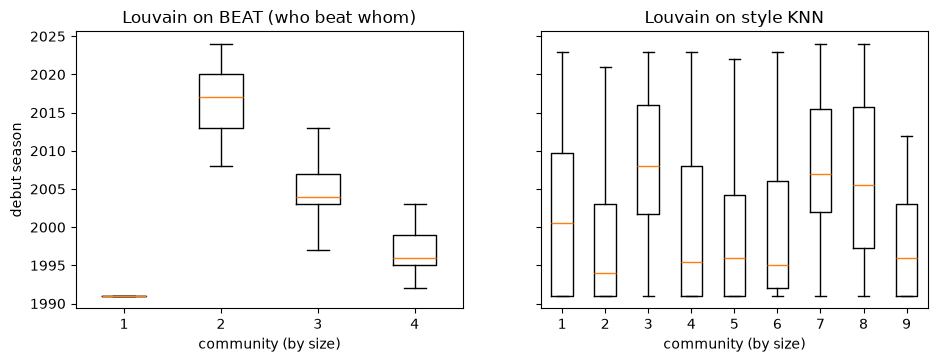

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, part) in zip(axes, partitions.items()):
    big = [c for c, n in Counter(part.values()).most_common() if n >= 10]
    ax.boxplot([[debut[i] for i in ids if part[i] == c] for c in big], showfliers=False)
    ax.set(title=name, xlabel="community (by size)")
axes[0].set_ylabel("debut season")
plt.show()

`BEAT` communities line up with generations (debut year), not with nationality or style; the style
communities mix eras and explain half of the style-feature variance. (The first `BEAT` community's debut
is 1991 because the data starts in 1991: those players debuted then or earlier.) That is why `/api/styles` uses
the KNN graph.

## 4. Match prediction vs the bookmakers

Logistic regression on graph features only, trained on matches up to 2021 and tested on 2022–2026
(`make train`; full report in `docs/model_report.md`). One past match, with the prices of every bookmaker
that priced it. Model probabilities are tagged *predicted*, odds and results *verified*.

In [12]:
match = db.read('''
MATCH (w:Player {name: 'Carlos Alcaraz'})-[:WON]->(m:Match {round: 'F'})<-[:LOST]-(l:Player {name: 'Novak Djokovic'})
MATCH (m)-[:PART_OF]->(:Tournament {name: 'Wimbledon', year: 2023})
RETURN m.id AS id, w.id AS winner, l.id AS loser''')[0]
p = predict.predict(db, match["winner"], match["loser"], None, match["id"])
print(f"{p.player1.name} vs {p.player2.name}, features from matches before {p.featuresBefore}")
print(f"model ({p.prediction.tag}): {p.player1.name} wins with p = {p.prediction.p1WinProbability:.3f}")
pd.DataFrame([m.model_dump() for m in p.market])

Carlos Alcaraz vs Novak Djokovic, features from matches before 2023-07-03
model (predicted): Carlos Alcaraz wins with p = 0.507


,tag,bookmaker,p1WinProbability,p1Odds,p2Odds
0,verified,Bet365,0.3678,2.63,1.53
1,verified,Pinnacle,0.3750,2.60,1.56


## 5. The agent: one answer and the guardrails at work

### A correct answer (replay of live-5, q01)

The model turns recorded in live run 5 (`openai/gpt-oss-120b`, 2026-10-24) are replayed through the real
agent loop: the tools query the graph now, and the verifier checks every claim tagged *verified* against
the tool results. Scores of all runs: `docs/agent_eval.md`.

In [13]:
from app.agent import graph as agent
from app.agent.replay import ReplayLLM
from app.agent.tools import ToolBox
from scripts import demo_guardrail

steps = get_settings().agent_max_steps
questions = {q["id"]: q["question"] for q in json.loads(Path("eval/questions_v2.json").read_text(encoding="utf-8"))}
answer = agent.ask(db, ReplayLLM.from_file(Path("eval/recordings/live-5/q01.json")), questions["q01"], steps,
                   "replay of live-5")
print("Q:", questions["q01"])
print("A:", answer.answer.summary)
display(pd.DataFrame([{"tool": t.tool, "arguments": t.arguments, "ok": t.success} for t in answer.trace]))
pd.DataFrame([{"claim": c.text, "tag": c.tag, "sources": c.sources} for c in answer.answer.claims])

Q: How many titles has Roger Federer won in the NetRank data?
A: Roger Federer has won 103 titles in the NetRank data.


,tool,arguments,ok
0,search_player,{'name': 'Roger Federer'},True
1,get_player,{'player_id': 103819},True


,claim,tag,sources
0,Roger Federer has won 103 titles in the NetRank data.,verified,[t2]


### An EXPLAIN rejection followed by a corrected retry (live-5, q21, recorded)

*How long was the longest match Roger Federer played at Wimbledon, and who was his opponent?* No typed tool
answers this, so the model used the fallback Cypher tool. These are its **first two queries, as recorded
live** (`eval/recordings/live-5/q21.json`), run again through the same tool call the agent uses. The first
guesses `m.duration` and `m.opponent`; the server's EXPLAIN reports both as unknown, and the rejection lists
the real property keys. The model's next query uses `m.minutes` and passes every layer.

The rest of q21 went wrong in ways the guardrail log explains: the retry sorted nulls first, a later query used
`exists()` (removed in Neo4j 5), and the retry cap refused a correct query. See
`docs/agent_eval/failure_breakdown.md` and decision log D78.

In [14]:
recorded = json.loads(Path("eval/recordings/live-5/q21.json").read_text(encoding="utf-8"))
first_two = [c["args"]["query"] for t in recorded for c in t.get("tool_calls", [])
             if c["name"] == "run_readonly_cypher"][:2]
print("Q:", questions["q21"])

before = db.read(demo_guardrail.COUNTS)[0]
toolbox = ToolBox(db)
for query in first_two:
    record, _ = toolbox.call("run_readonly_cypher", {"query": query})
    print()
    print("model's Cypher:", query)
    print("pipeline:", f"accepted, {record.result['rowCount']} row(s): {record.result['rows']}" if record.success
          else f"REJECTED by layer '{record.guardrail}': {record.error}")
    display(pd.DataFrame(demo_guardrail.layer_by_layer(db, query), columns=["layer, run on its own", "verdict"]))
print("graph unchanged:", db.read(demo_guardrail.COUNTS)[0] == before)

Q: How long, in minutes, was the longest match Roger Federer played at Wimbledon, and who was his opponent?

model's Cypher: MATCH (p:Player {name: 'Roger Federer'})-[:WON|:LOST]->(m:Match)-[:PART_OF]->(t:Tournament {name: 'Wimbledon'}) RETURN m.id AS match_id, m.duration AS minutes, m.round AS round, m.opponent AS opponent_name ORDER BY minutes DESC LIMIT 1
pipeline: REJECTED by layer 'explain': [explain] server reports: warn: property key does not exist. The property `duration` does not exist. Verify that the spelling is correct; warn: property key does not exist. The property `opponent` does not exist. Verify that the spelling is correct. Known properties: Player: id, name, firstName, lastName, ioc, hand, dob, height, prestige, prestigeRank, styleId; Match: id, date, round, score, surface, bestOf, minutes, walkover, retired, marketAvgWinnerOdds, marketAvgLoserOdds, marketMaxWinnerOdds, marketMaxLoserOdds; Tournament: id, name, year, level (G, M, A, F), levelName, surface, drawSize, 

,"layer, run on its own",verdict
0,1 static,passes
1,2 schema,passes
2,3 explain,REJECTS: [explain] server reports: warn: property key does not exist. The pr...
3,5 READ transaction,passes



model's Cypher: MATCH (p:Player {name: "Roger Federer"})-[:WON|:LOST]->(m:Match)-[:PART_OF]->(t:Tournament {name: "Wimbledon"}) MATCH (opp:Player)-[:WON|:LOST]->(m) WHERE opp <> p RETURN m.minutes AS minutes, opp.name AS opponent ORDER BY minutes DESC LIMIT 1
pipeline: accepted, 1 row(s): [{'minutes': None, 'opponent': 'Roberto Bautista Agut'}]


,"layer, run on its own",verdict
0,1 static,passes
1,2 schema,passes
2,3 explain,passes
3,5 READ transaction,passes


graph unchanged: True


### A write query, stopped by the guardrails (scripted turn)

No live run produced a write query (the model refused it every time), so this model turn is **scripted**, in
the recording format (`eval/demo/guardrail_turns.json`, also used by `make demo-guardrail`). Each layer is then
run on its own, to show that a later layer would still stop a write the earlier ones missed.

In [15]:
source, turns = demo_guardrail.load(demo_guardrail.DEFAULT)
write = [c["args"]["query"] for t in turns for c in t.get("tool_calls", [])
         if c["name"] == "run_readonly_cypher" and " SET " in c["args"]["query"]]
print("turns:", source[:120], "...")

before = db.read(demo_guardrail.COUNTS)[0]
toolbox = ToolBox(db)
for query in write:
    record, _ = toolbox.call("run_readonly_cypher", {"query": query})
    print()
    print("model's Cypher:", query)
    print("pipeline:", f"accepted, {record.result['rowCount']} row(s): {record.result['rows']}" if record.success
          else f"REJECTED by layer '{record.guardrail}': {record.error}")
    display(pd.DataFrame(demo_guardrail.layer_by_layer(db, query), columns=["layer, run on its own", "verdict"]))
print("graph unchanged:", db.read(demo_guardrail.COUNTS)[0] == before)

turns:

 Scripted model turns in the recording format (no live run has produced a write query: gpt-oss-120b refused q18 or was th ...

model's Cypher: MATCH (p:Player) SET p.name = 'hacked' RETURN count(p)
pipeline: REJECTED by layer 'static': [static] write or admin clause not allowed: SET


,"layer, run on its own",verdict
0,1 static,REJECTS: [static] write or admin clause not allowed: SET
1,2 schema,passes
2,3 explain,REJECTS: [explain] plan contains write operators ['SetProperty']
3,5 READ transaction,REJECTS (server): Neo.ClientError.Statement.AccessMode


graph unchanged: True


In [16]:
db.close()